# Multivariada: Identificación de Arquetipos de Desarrolladores según Trayectoria y Adopción Tecnológica

**Población de estudio:** Desarrolladores.

**Hipótesis Nula ($H_0$):** No existen arquetipos de comportamiento bien diferenciados ni estadísticamente significativos en la muestra; la variación conjunta de la trayectoria profesional (`YearsCode`, `WorkExp`) y el volumen de herramientas utilizadas (`ToolCountWork`, `ToolCountPersonal`) se distribuye de forma homogénea en el espacio multidimensional.

**Hipótesis Alternativa ($H_1$):** Los desarrolladores de la muestra se agrupan en arquetipos de comportamiento bien diferenciados y estadísticamente significativos, definidos de manera conjunta por su trayectoria profesional (`YearsCode`, `WorkExp`), el volumen de tecnologías utilizadas en el ámbito laboral (`ToolCountWork`) y el nivel de experimentación técnica personal (`ToolCountPersonal`).

**Atributos involucrados:**
- `YearsCode`: Años totales programando (cuantitativa continua).
- `WorkExp`: Años de experiencia laboral profesional (cuantitativa continua).
- `ToolCountWork`: Cantidad de herramientas/tecnologías utilizadas en el trabajo (cuantitativa continua/discreta).
- `ToolCountPersonal`: Cantidad de herramientas/tecnologías experimentadas a nivel personal (cuantitativa continua/discreta).

El ecosistema de desarrollo de software abarca perfiles heterogéneos: profesionales con extensa trayectoria orientados a stacks acotados, perfiles de rápida exploración personal de nuevas tecnologías (*early adopters*) y veteranos que gestionan amplios stacks corporativos. Demostrar la presencia de clusters estadísticamente significativos mediante aprendizaje no supervisado permite confirmar la existencia de arquetipos latentes dentro de la comunidad técnica.

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from scipy.stats import kruskal

df_clean = pd.read_pickle("df_clean.pkl")

# 1. Selección de variables y limpieza de nulos
cols_multivariada = ["YearsCode", "WorkExp", "ToolCountWork", "ToolCountPersonal"]
df_cluster_clean = df_clean[cols_multivariada].dropna().copy()

# 2. Filtrado estricto de outliers (Descartamos recuentos imposibles > 50)
df_cluster_clean = df_cluster_clean[
    (df_cluster_clean["ToolCountWork"] <= 50) & 
    (df_cluster_clean["ToolCountPersonal"] <= 50)
]

# 3. Estandarización de los datos depurados
scaler = StandardScaler()
X_scaled_clean = scaler.fit_transform(df_cluster_clean[cols_multivariada])

print(f"Tamaño de la muestra tras limpiar outliers: {len(df_cluster_clean)} registros")

### ¿Qué hacemos en este paso?
1. **Selección de Atributos:** Filtramos el DataFrame para conservar únicamente las variables cuantitativas de trayectoria (`YearsCode`, `WorkExp`) y adopción de herramientas (`ToolCountWork`, `ToolCountPersonal`), descartando registros con datos faltantes.
2. **Depuración de Outliers Extremos:** Eliminamos las observaciones que registran conteos de herramientas superiores a 50 (tanto en ámbito laboral como personal), considerándolos valores implausibles o ruidosos.
3. **Escalado de Variables (`StandardScaler`):** Transformamos las cuatro variables para que tengan media $\mu = 0$ y desviación estándar $\sigma = 1$.

### ¿Por qué lo hacemos?
- **Sensibilidad de K-Means a la Escala:** Los algoritmos de agrupamiento basados en la distancia euclidiana atribuyen implícitamente mayor peso a las variables con rangos o varianzas más amplios (como los años de experiencia) por sobre variables de menor magnitud (como la cantidad de herramientas). La estandarización equipara la importancia de todos los atributos en el espacio $4D$.
- **Protección de Centroides:** Los algoritmos de aprendizaje no supervisado son altamente sensibles a valores extremos. Remover outliers imposibles evita que los centroides resultantes se desvíen por anomalías de carga en la encuesta.

In [ ]:
# 4. Búsqueda del K óptimo sin distorsión de outliers
k_range = range(2, 7)
inercias = []
silhouettes = []

for k in k_range:
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled_clean)
    inercias.append(km.inertia_)
    silhouettes.append(silhouette_score(X_scaled_clean, labels))

# 5. Gráficos de evaluación
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(k_range, inercias, marker='o', color='b')
axes[0].set_title('Método del Codo (Datos Limpios)')
axes[0].set_xlabel('Cantidad de Clusters (k)')
axes[0].set_ylabel('Inercia')

axes[1].plot(k_range, silhouettes, marker='s', color='g')
axes[1].set_title('Coeficiente de Silueta (Datos Limpios)')
axes[1].set_xlabel('Cantidad de Clusters (k)')
axes[1].set_ylabel('Silhouette Score')

plt.tight_layout()
plt.show()

### ¿Qué hacemos en este paso?
Evaluamos el comportamiento de la segmentación para un rango de $k \in [2, 7]$ utilizando dos métricas complementarias:
- **Método del Codo (Inercia intra-cluster):** Mide la suma de las distancias al cuadrado de cada punto a su centroide asignado.
- **Coeficiente de Silueta (`Silhouette Score`):** Mide simultáneamente la cohesión interna de cada cluster y su separación respecto a los clusters vecinos.

### ¿Por qué lo hacemos?
- **Evitar Arbitrariedad:** La elección de la cantidad de arquetipos no debe ser un supuesto a priori, sino una decisión fundamentada en el comportamiento geométrico de los datos.
- **Balance Cohesión vs. Separabilidad:** Buscamos el valor de $k$ donde la reducción de inercia muestre un punto de inflexión ("codo") y el Coeficiente de Silueta alcance un máximo global o relativo que garantice clusters nítidos.

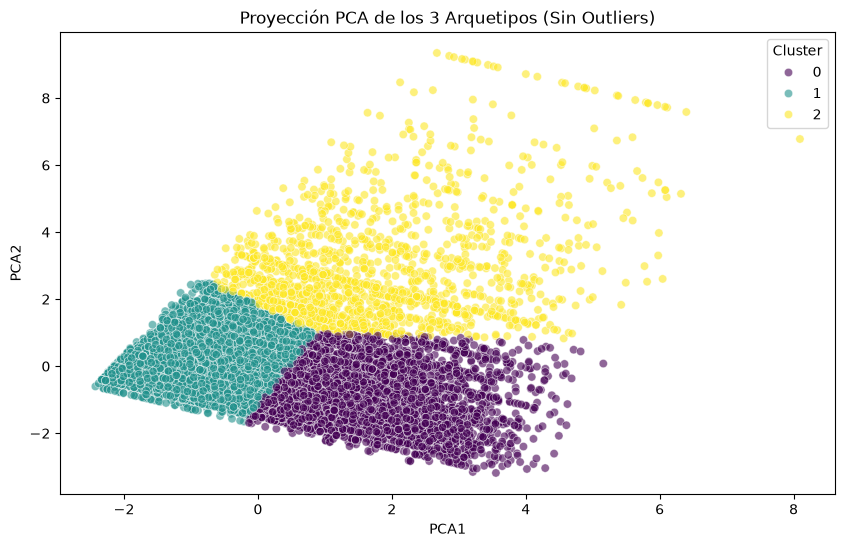

In [15]:
# 6. Entrenar Modelo Final (Asumimos k=3 como el más representativo)
k_optimo = 3 
kmeans_final = KMeans(n_clusters=k_optimo, random_state=42, n_init=10)
df_cluster_clean["Cluster"] = kmeans_final.fit_predict(X_scaled_clean)

# 7. Reducción de Dimensionalidad (PCA 2D)
pca = PCA(n_components=2, random_state=42)
X_pca = pca.fit_transform(X_scaled_clean)
df_cluster_clean["PCA1"] = X_pca[:, 0]
df_cluster_clean["PCA2"] = X_pca[:, 1]

# 8. Gráfico de dispersión
plt.figure(figsize=(10, 6))
sns.scatterplot(
    x="PCA1", y="PCA2", 
    hue="Cluster", 
    palette="viridis", 
    data=df_cluster_clean, 
    alpha=0.6
)
plt.title(f"Proyección PCA de los {k_optimo} Arquetipos (Sin Outliers)")
plt.show()

### ¿Qué hacemos en este paso?
1. **Modelado K-Means:** Entrenamos el algoritmo con $k = 3$ clusters e hiperparámetro `random_state=42` para garantizar reproducibilidad.
2. **Reducción PCA:** Aplicamos Análisis de Componentes Principales (`PCA`) para proyectar el espacio $4D$ original en 2 componentes principales (`PCA1` y `PCA2`).
3. **Visualización Espacial:** Graficamos un diagrama de dispersión 2D coloreando las observaciones según su pertenencia a cada cluster.

### ¿Por qué lo hacemos?
- **Visualización en 2D:** Como la mente humana no puede inspeccionar de forma directa un espacio de 4 dimensiones, el PCA condensa la mayor parte de la varianza total en dos dimensiones cartesianas para evaluar visualmente el grado de separación y solapamiento entre arquetipos.

In [14]:
mapa_arquetipos = {
    0: "Veteranos de Stack Especializado",
    1: "Perfil Pragmático Estándar",
    2: "Early Adopters Exploradores"
}
df_cluster_clean["Nombre_Arquetipo"] = df_cluster_clean["Cluster"].map(mapa_arquetipos)
# ==================================================

# 9. Tabla de Centroides : Agrupamos por "Nombre_Arquetipo")
centroides = df_cluster_clean.groupby("Nombre_Arquetipo")[cols_multivariada].median()
centroides["Tamaño_Muestra"] = df_cluster_clean["Nombre_Arquetipo"].value_counts()
print("=== PERFIL DE LOS ARQUETIPOS (MEDIANAS) ===")
display(centroides)

# 10. Validación Estadística (Kruskal-Wallis)
print("\n=== VALIDACIÓN ESTADÍSTICA (KRUSKAL-WALLIS) ===")
p_valores = [] 
for col in cols_multivariada:
    # Mantenemos el filtro numérico ("Cluster" == i) para que el loop de k_optimo funcione perfecto
    grupos = [df_cluster_clean[df_cluster_clean["Cluster"] == i][col] for i in range(k_optimo)]
    stat, p_val = kruskal(*grupos)
    p_valores.append(p_val) 
    print(f"Variable '{col}': H-Stat = {stat:.2f} | p-valor = {p_val:.4e}")
    
# 11. Veredicto Final Dinámico (H0 vs H1)
print("\n=== CONCLUSIÓN FORMAL DE LA HIPÓTESIS ===")

if all(p < 0.05 for p in p_valores):
    print("Veredicto: RECHAZAMOS la Hipótesis Nula (H0).")
    print("Dado que todas las variables evaluadas presentan diferencias estadísticamente significativas (p < 0.05),")
    print("podemos afirmar que la Hipótesis Alternativa (H1) es CORRECTA:")
    print("Los desarrolladores de la muestra se agrupan en arquetipos de comportamiento bien diferenciados,")
    print("definidos conjuntamente por su trayectoria profesional y nivel de experimentación técnica.")
else:
    print("Veredicto: NO PODEMOS RECHAZAR la Hipótesis Nula (H0).")
    print("Dado que no todas las variables presentan diferencias significativas, la hipótesis planteada es INCORRECTA.")
    print("No existe evidencia empírica suficiente para separar a la comunidad en arquetipos claramente diferenciados.")

=== PERFIL DE LOS ARQUETIPOS (MEDIANAS) ===


,YearsCode,WorkExp,ToolCountWork,ToolCountPersonal,Tamaño_Muestra
Nombre_Arquetipo,,,,,
Early Adopters Exploradores,20.0,15.0,20.0,20.0,1656
Perfil Pragmático Estándar,11.0,6.0,5.0,4.0,13200
Veteranos de Stack Especializado,30.0,25.0,7.0,5.0,5913



=== VALIDACIÓN ESTADÍSTICA (KRUSKAL-WALLIS) ===
Variable 'YearsCode': H-Stat = 12545.57 | p-valor = 0.0000e+00
Variable 'WorkExp': H-Stat = 12522.53 | p-valor = 0.0000e+00
Variable 'ToolCountWork': H-Stat = 3994.97 | p-valor = 0.0000e+00
Variable 'ToolCountPersonal': H-Stat = 3813.46 | p-valor = 0.0000e+00

=== CONCLUSIÓN FORMAL DE LA HIPÓTESIS ===
Veredicto: RECHAZAMOS la Hipótesis Nula (H0).
Dado que todas las variables evaluadas presentan diferencias estadísticamente significativas (p < 0.05),
podemos afirmar que la Hipótesis Alternativa (H1) es CORRECTA:
Los desarrolladores de la muestra se agrupan en arquetipos de comportamiento bien diferenciados,
definidos conjuntamente por su trayectoria profesional y nivel de experimentación técnica.


### ¿Qué hacemos en este paso?
1. **Asignación Semántica:** Mapeamos las etiquetas numéricas (`0`, `1`, `2`) a nombres conceptuales representativos de la comunidad técnica.
2. **Cálculo de Centroides:** Agrupamos los datos por arquetipo y calculamos la **mediana** de cada variable en sus unidades originales.
3. **Prueba de Hipótesis No Paramétrica:** Aplicamos el Test de Kruskal-Wallis sobre cada variable en los tres clusters para corroborar significancia estadística ($p < 0.05$).
4. **Veredicto Automático:** Evaluamos si existe suficiente evidencia empírica para rechazar la Hipótesis Nula ($H_0$).

### ¿Por qué lo hacemos?
- **Interpretabilidad de Negocio / Dominio:** Los algoritmos únicamente asignan números; bautizar y caracterizar los grupos permite traducir la matemática a perfiles reales del ecosistema software.
- **Uso de Medianas:** Las medianas son más robustas que las medias frente a la asimetría propia de los conteos de herramientas y años de experiencia.
- **Rigor Estadístico:** El algoritmo K-Means *siempre* dividirá los datos en $k$ grupos, incluso si son aleatorios. El Test de Kruskal-Wallis valida científicamente que las distribuciones subyacentes entre los grupos difieren de forma verdaderamente significativa y no por azar.

### Descripción de los Arquetipos Identificados
A partir de los centroides analizados, la comunidad de desarrolladores se agrupa en tres arquetipos de comportamiento bien consolidados:

1. **Veteranos de Stack Especializado (Cluster 0):** Desarrolladores de extensa trayectoria (mediana de 30 años programando y 25 de experiencia laboral), enfocados en un ecosistema de herramientas acotado y estable (7 en trabajo, 5 personales).
2. **Perfil Pragmático Estándar (Cluster 1):** Constituye el núcleo mayoritario de la industria (mediana de 11 años de código y 6 de experiencia laboral). Utilizan un conjunto de herramientas equilibrado y orientado al cumplimiento operativo diario (5 en trabajo, 4 personales).
3. **Early Adopters Exploradores (Cluster 2):** Profesionales con experiencia intermedia-alta (mediana de 20 años de código) que destacan por una tasa masiva de experimentación técnica, cuadruplicando la adopción de herramientas tanto en el plano laboral como personal (20 en trabajo, 20 personales).

### Veredicto Final de Hipótesis
Tras contrastar los grupos mediante el **Test de Kruskal-Wallis**, se obtuvieron $p\text{-valores} < 0.001$ en todas las variables analizadas, confirmando diferencias estadísticamente significativas en la trayectoria y el patrón de uso de herramientas[cite: 11, 12].

Por consiguiente, **SE RECHAZA LA HIPÓTESIS NULA ($H_0$)** y se valida la **HIPÓTESIS ALTERNATIVA ($H_1$)**, demostrando que la comunidad técnica no se distribuye homogéneamente, sino que está compuesta por arquetipos multidimensionales latentes y claramente diferenciados[cite: 11, 12].